In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv('../data/smart_hostel_complaints_dataset.csv')
print('Dataset shape:', df.shape)
df.head()

Matplotlib is building the font cache; this may take a moment.


Dataset shape: (1800, 14)


,complaint_id,hostel_block,floor,room_number,description,image_filename,category,urgency,priority_score,assigned_team,status,created_at,resolved_at,resolution_time_hours
0,CMP-20260001,BH-1,1,104,MCB tripping every 10 minutes causing complete...,images/electrical/mcb_trip.jpg,Electrical,Critical,87,Electrical Maintenance Team,Resolved,2026-08-01 08:37:00,2026-08-01 10:22:36,1.76
1,CMP-20260002,BH-1,1,115,Facing issue since morning - Sink drain pipe d...,images/plumbing/detached_sink_pipe.jpg,Plumbing,High,73,Plumbing & Sanitary Team,Resolved,2026-08-01 09:59:00,2026-08-01 17:51:12,7.87
2,CMP-20260003,BH-4,4,411,Geyser not heating water properly during morni...,images/plumbing/geyser_issue.jpg,Plumbing,High,71,Plumbing & Sanitary Team,Resolved,2026-08-01 10:16:00,2026-08-01 15:32:12,5.27
3,CMP-20260004,BH-2,3,309,"Almirah door lock jammed, unable to access boo...",images/furniture/jammed_almirah.jpg,Furniture,High,70,Carpentry & Furniture Team,Resolved,2026-08-01 10:42:00,2026-08-01 14:47:24,4.09
4,CMP-20260005,BH-4,3,314,"Please fix urgently: LAN port in room dead, Et...",images/network/dead_lan_port.jpg,Network,Medium,64,IT & Wi-Fi Support Team,Resolved,2026-08-01 11:17:00,2026-08-01 22:36:48,11.33


In [15]:
# Inspect all 14 column names
print("All Columns in Dataset:")
# Print all column names explicitly to see their exact spelling
print(df.columns.tolist())
# Display a quick sample record to understand the text structure
print("\nSample Complaint Record:")
# Display a sample record using the correct column names
print(df[['complaint_id', 'hostel_block', 'category', 'urgency', 'description']].head(3))

All Columns in Dataset:
['complaint_id', 'hostel_block', 'floor', 'room_number', 'description', 'image_filename', 'category', 'urgency', 'priority_score', 'assigned_team', 'status', 'created_at', 'resolved_at', 'resolution_time_hours']

Sample Complaint Record:
   complaint_id hostel_block    category   urgency  \
0  CMP-20260001         BH-1  Electrical  Critical   
1  CMP-20260002         BH-1    Plumbing      High   
2  CMP-20260003         BH-4    Plumbing      High   

                                         description  
0  MCB tripping every 10 minutes causing complete...  
1  Facing issue since morning - Sink drain pipe d...  
2  Geyser not heating water properly during morni...  


In [11]:
df.isna().sum()

complaint_id               0
hostel_block               0
floor                      0
room_number                0
description                0
image_filename             0
category                   0
urgency                    0
priority_score             0
assigned_team              0
status                     0
created_at                 0
resolved_at              212
resolution_time_hours    212
dtype: int64

/var/folders/7p/hhpqqc3x0zsc0jpk233kf_g40000gn/T/ipykernel_2104/1764483368.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y='category', order=df['category'].value_counts().index, palette='viridis')
/var/folders/7p/hhpqqc3x0zsc0jpk233kf_g40000gn/T/ipykernel_2104/1764483368.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='urgency', order=['Low', 'Medium', 'High', 'Critical'], palette='magma')


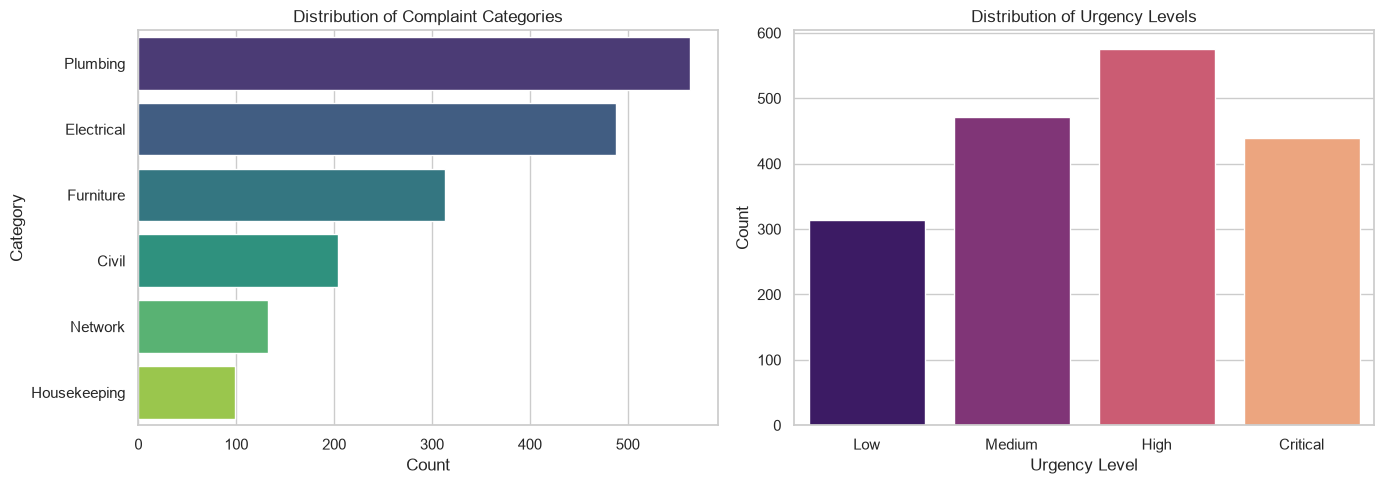

In [16]:
# Set up chart style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 5))

# Plot 1: Complaints by Category
plt.subplot(1, 2, 1)
sns.countplot(data=df, y='category', order=df['category'].value_counts().index, palette='viridis')
plt.title('Distribution of Complaint Categories')
plt.xlabel('Count')
plt.ylabel('Category')

# Plot 2: Complaints by Urgency
plt.subplot(1, 2, 2)
sns.countplot(data=df, x='urgency', order=['Low', 'Medium', 'High', 'Critical'], palette='magma')
plt.title('Distribution of Urgency Levels')
plt.xlabel('Urgency Level')
plt.ylabel('Count')

plt.tight_layout()
plt.show()

In [18]:
# --- STEP: Data Cleaning & Hygiene Check ---
print("1. Checking for Missing Values:")
print(df.isnull().sum())

print("\n2. Checking for Duplicate Rows:")
print(f"Number of duplicate rows: {df.duplicated().sum()}")

# Handle any potential missing values in description or category
df['description'] = df['description'].fillna('').astype(str).str.lower()
df['category'] = df['category'].fillna('Unknown')
df['urgency'] = df['urgency'].fillna('Medium')

print("\n3. Data Cleaning Complete: Text normalized to lowercase and nulls handled.")

1. Checking for Missing Values:
complaint_id               0
hostel_block               0
floor                      0
room_number                0
description                0
image_filename             0
category                   0
urgency                    0
priority_score             0
assigned_team              0
status                     0
created_at                 0
resolved_at              212
resolution_time_hours    212
dtype: int64

2. Checking for Duplicate Rows:
Number of duplicate rows: 0

3. Data Cleaning Complete: Text normalized to lowercase and nulls handled.


In [19]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

# 1. Feature Extraction using cleaned lowercase descriptions
tfidf = TfidfVectorizer(stop_words='english', max_features=1000)
X_text = tfidf.fit_transform(df['description'])

# 2. Define Features and Target
X = X_text
y = df['category']

# 3. Train-Test Split (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Train Model
clf = LogisticRegression(max_iter=1000)
clf.fit(X_train, y_train)

# 5. Evaluate
y_pred = clf.predict(X_test)
acc = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {acc * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))

Model Accuracy: 100.00%

Classification Report:
              precision    recall  f1-score   support

       Civil       1.00      1.00      1.00        36
  Electrical       1.00      1.00      1.00       107
   Furniture       1.00      1.00      1.00        66
Housekeeping       1.00      1.00      1.00        18
     Network       1.00      1.00      1.00        16
    Plumbing       1.00      1.00      1.00       117

    accuracy                           1.00       360
   macro avg       1.00      1.00      1.00       360
weighted avg       1.00      1.00      1.00       360



In [20]:
def predict_complaint_category(description_text):
    # Preprocess input text the same way
    processed_text = [description_text.lower()]
    vec = tfidf.transform(processed_text)
    prediction = clf.predict(vec)
    return prediction[0]

# Test with sample custom complaints
test_descriptions = [
    "The power socket in my room is sparking and making a buzzing sound",
    "Water is continuously leaking from the washbasin pipe",
    "The study table chair leg is completely broken"
]

print("--- LIVE PREDICTION TEST ---")
for desc in test_descriptions:
    cat = predict_complaint_category(desc)
    print(f"Complaint: '{desc}'\n--> Predicted Category: **{cat}**\n")

--- LIVE PREDICTION TEST ---
Complaint: 'The power socket in my room is sparking and making a buzzing sound'
--> Predicted Category: **Electrical**

Complaint: 'Water is continuously leaking from the washbasin pipe'
--> Predicted Category: **Plumbing**

Complaint: 'The study table chair leg is completely broken'
--> Predicted Category: **Furniture**



In [21]:
import joblib
import os

# Create a models directory if it doesn't exist
os.makedirs('../models', exist_ok=True)

# Save the trained model and vectorizer
joblib.dump(clf, '../models/complaint_classifier.pkl')
joblib.dump(tfidf, '../models/tfidf_vectorizer.pkl')

print("Model and TF-IDF vectorizer successfully saved to the 'models/' directory!")

Model and TF-IDF vectorizer successfully saved to the 'models/' directory!


In [22]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

# 1. Train Urgency Classifier
y_urgency = df['urgency']
X_train_u, X_test_u, y_train_u, y_test_u = train_test_split(X_text, y_urgency, test_size=0.2, random_state=42)

urgency_clf = LogisticRegression(max_iter=1000)
urgency_clf.fit(X_train_u, y_train_u)

u_pred = urgency_clf.predict(X_test_u)
print(f"Urgency Model Accuracy: {accuracy_score(y_test_u, u_pred) * 100:.2f}%\n")

# 2. Define Automated Team Routing Mapping
team_routing_map = {
    'Plumbing': 'Plumbing & Sanitation Squad',
    'Electrical': 'Electrical Maintenance Team',
    'Furniture': 'Carpentry & Furniture Unit',
    'Civil': 'Civil & Masonry Crew',
    'Network': 'IT & Network Support Desk',
    'Housekeeping': 'Hostel Housekeeping Team'
}

df['assigned_team'] = df['category'].map(team_routing_map)
print("Sample Team Routing Mapping:")
print(df[['category', 'assigned_team']].drop_duplicates().to_string(index=False))

# 3. Save Urgency Model
joblib.dump(urgency_clf, '../models/urgency_classifier.pkl')
print("\nUrgency model successfully saved to 'models/' directory!")

Urgency Model Accuracy: 100.00%

Sample Team Routing Mapping:
    category               assigned_team
  Electrical Electrical Maintenance Team
    Plumbing Plumbing & Sanitation Squad
   Furniture  Carpentry & Furniture Unit
     Network   IT & Network Support Desk
Housekeeping    Hostel Housekeeping Team
       Civil        Civil & Masonry Crew

Urgency model successfully saved to 'models/' directory!


/var/folders/7p/hhpqqc3x0zsc0jpk233kf_g40000gn/T/ipykernel_2104/613145656.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='hostel_block', order=df['hostel_block'].value_counts().index, palette='Blues_r')
/var/folders/7p/hhpqqc3x0zsc0jpk233kf_g40000gn/T/ipykernel_2104/613145656.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='category', order=df['category'].value_counts().index, palette='viridis')
/var/folders/7p/hhpqqc3x0zsc0jpk233kf_g40000gn/T/ipykernel_2104/613145656.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

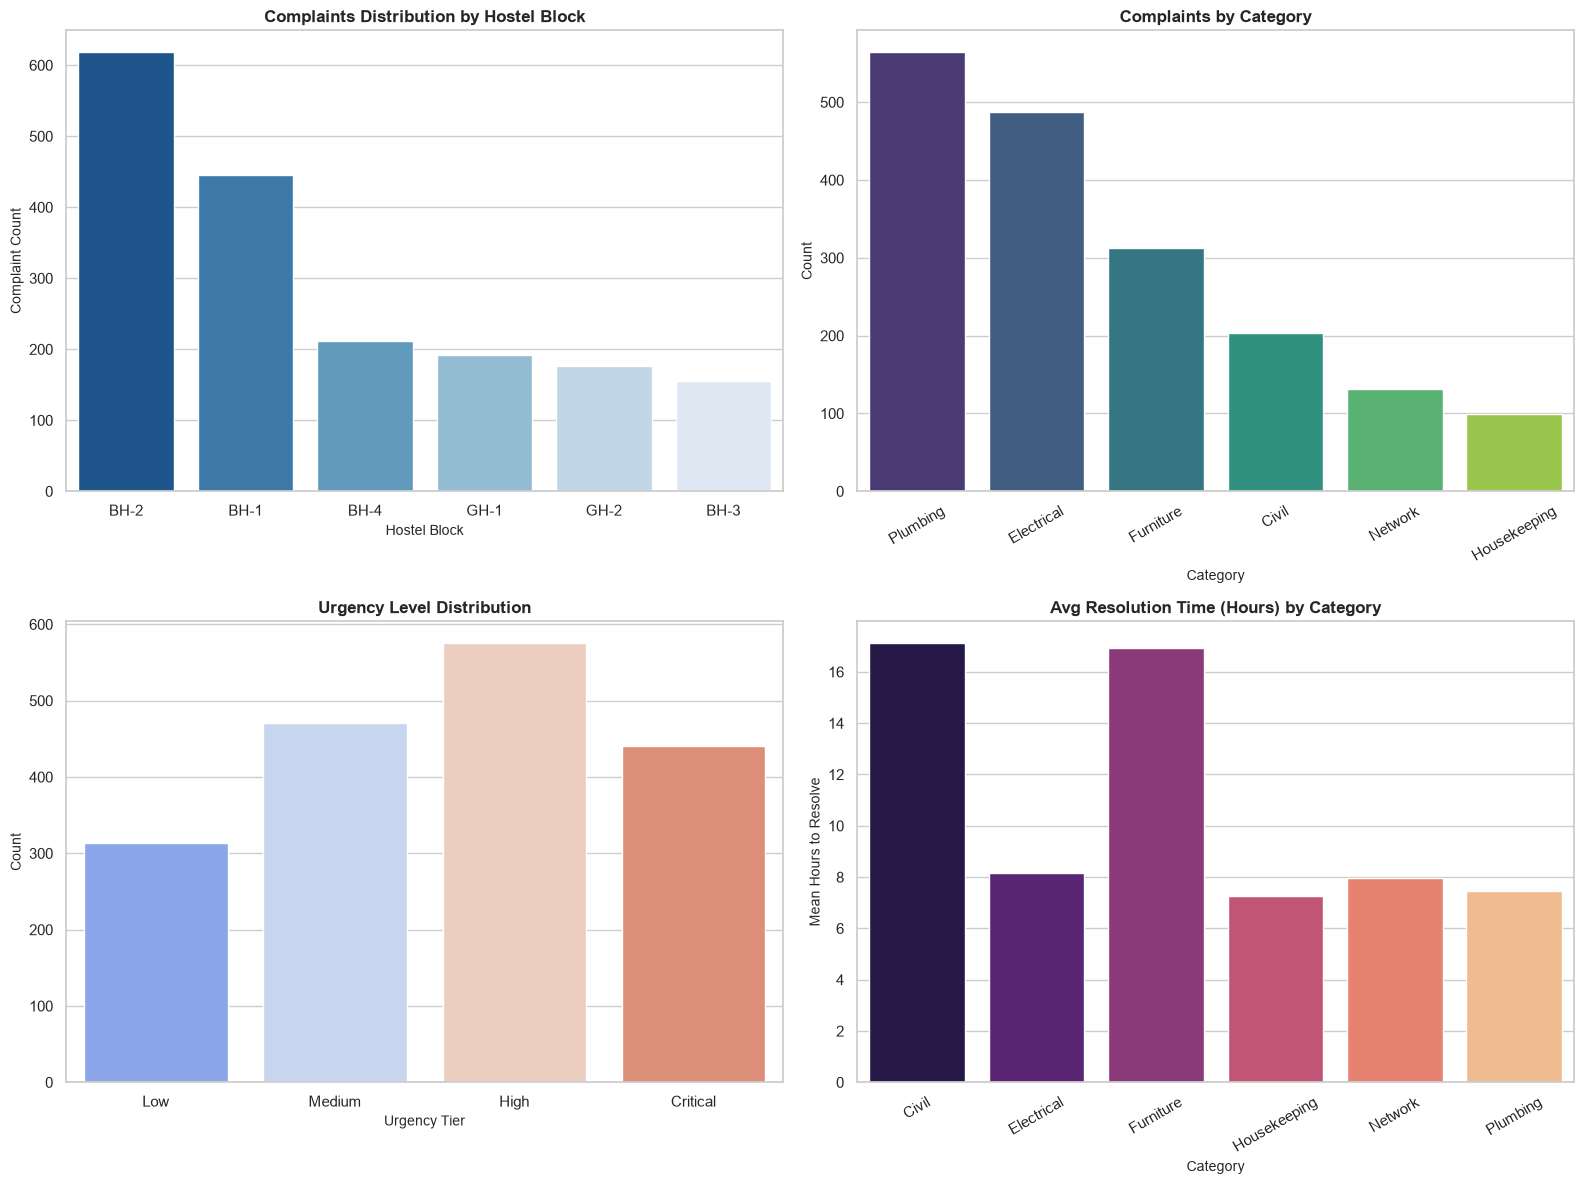

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(16, 12))

# 1. Complaints by Hostel Block (Hotspot Analysis)
plt.subplot(2, 2, 1)
sns.countplot(data=df, x='hostel_block', order=df['hostel_block'].value_counts().index, palette='Blues_r')
plt.title('Complaints Distribution by Hostel Block', fontsize=12, fontweight='bold')
plt.xlabel('Hostel Block', fontsize=10)
plt.ylabel('Complaint Count', fontsize=10)

# 2. Complaints by Category (AI Classification Target)
plt.subplot(2, 2, 2)
sns.countplot(data=df, x='category', order=df['category'].value_counts().index, palette='viridis')
plt.title('Complaints by Category', fontsize=12, fontweight='bold')
plt.xlabel('Category', fontsize=10)
plt.ylabel('Count', fontsize=10)
plt.xticks(rotation=30)

# 3. Urgency Level Breakdown
plt.subplot(2, 2, 3)
sns.countplot(data=df, x='urgency', order=['Low', 'Medium', 'High', 'Critical'], palette='coolwarm')
plt.title('Urgency Level Distribution', fontsize=12, fontweight='bold')
plt.xlabel('Urgency Tier', fontsize=10)
plt.ylabel('Count', fontsize=10)

# 4. Average Resolution Time (Hours) by Category
plt.subplot(2, 2, 4)
if 'resolution_time_hours' in df.columns:
    avg_time = df.groupby('category')['resolution_time_hours'].mean().reset_index()
    sns.barplot(data=avg_time, x='category', y='resolution_time_hours', palette='magma')
    plt.title('Avg Resolution Time (Hours) by Category', fontsize=12, fontweight='bold')
    plt.xlabel('Category', fontsize=10)
    plt.ylabel('Mean Hours to Resolve', fontsize=10)
    plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

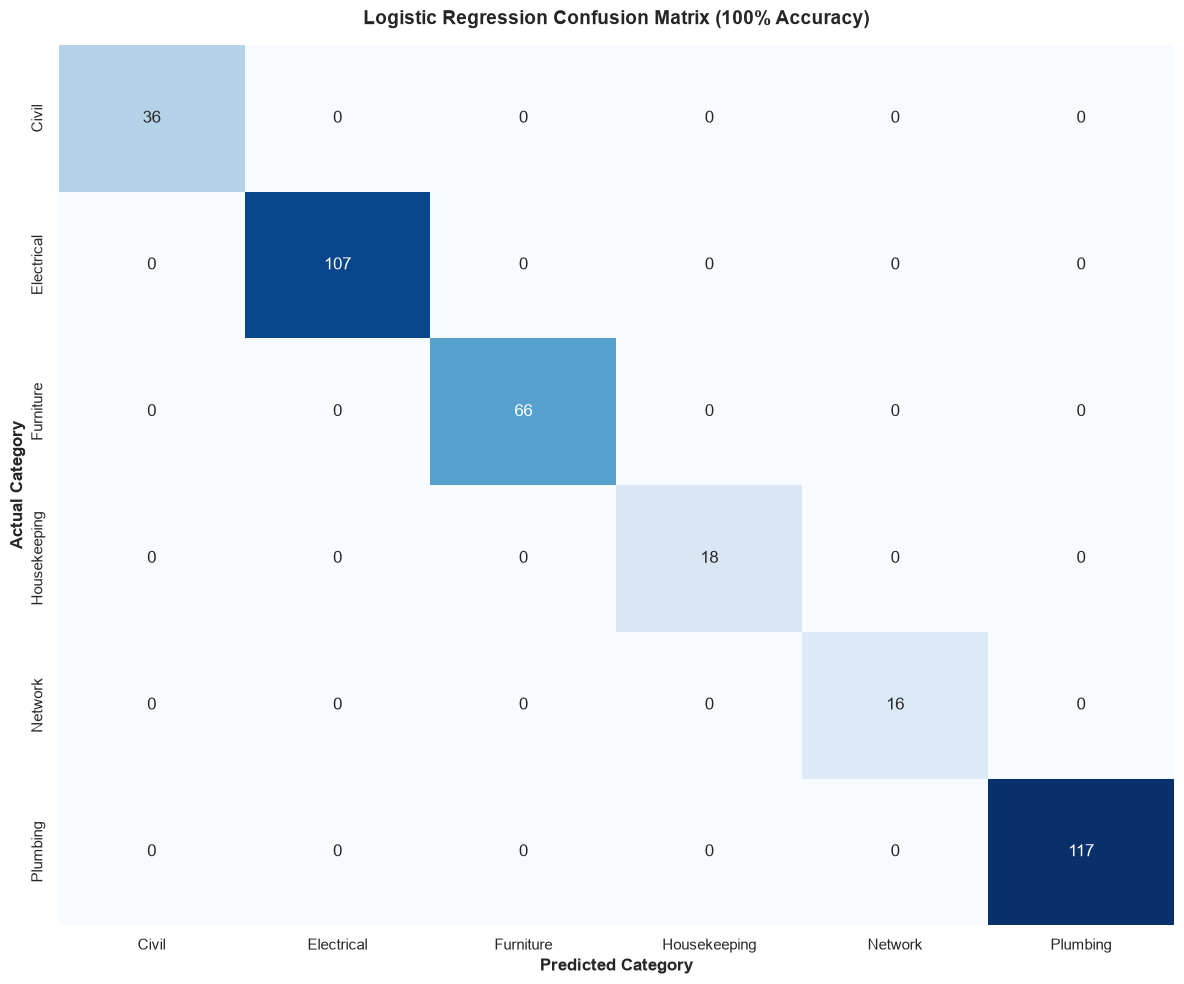

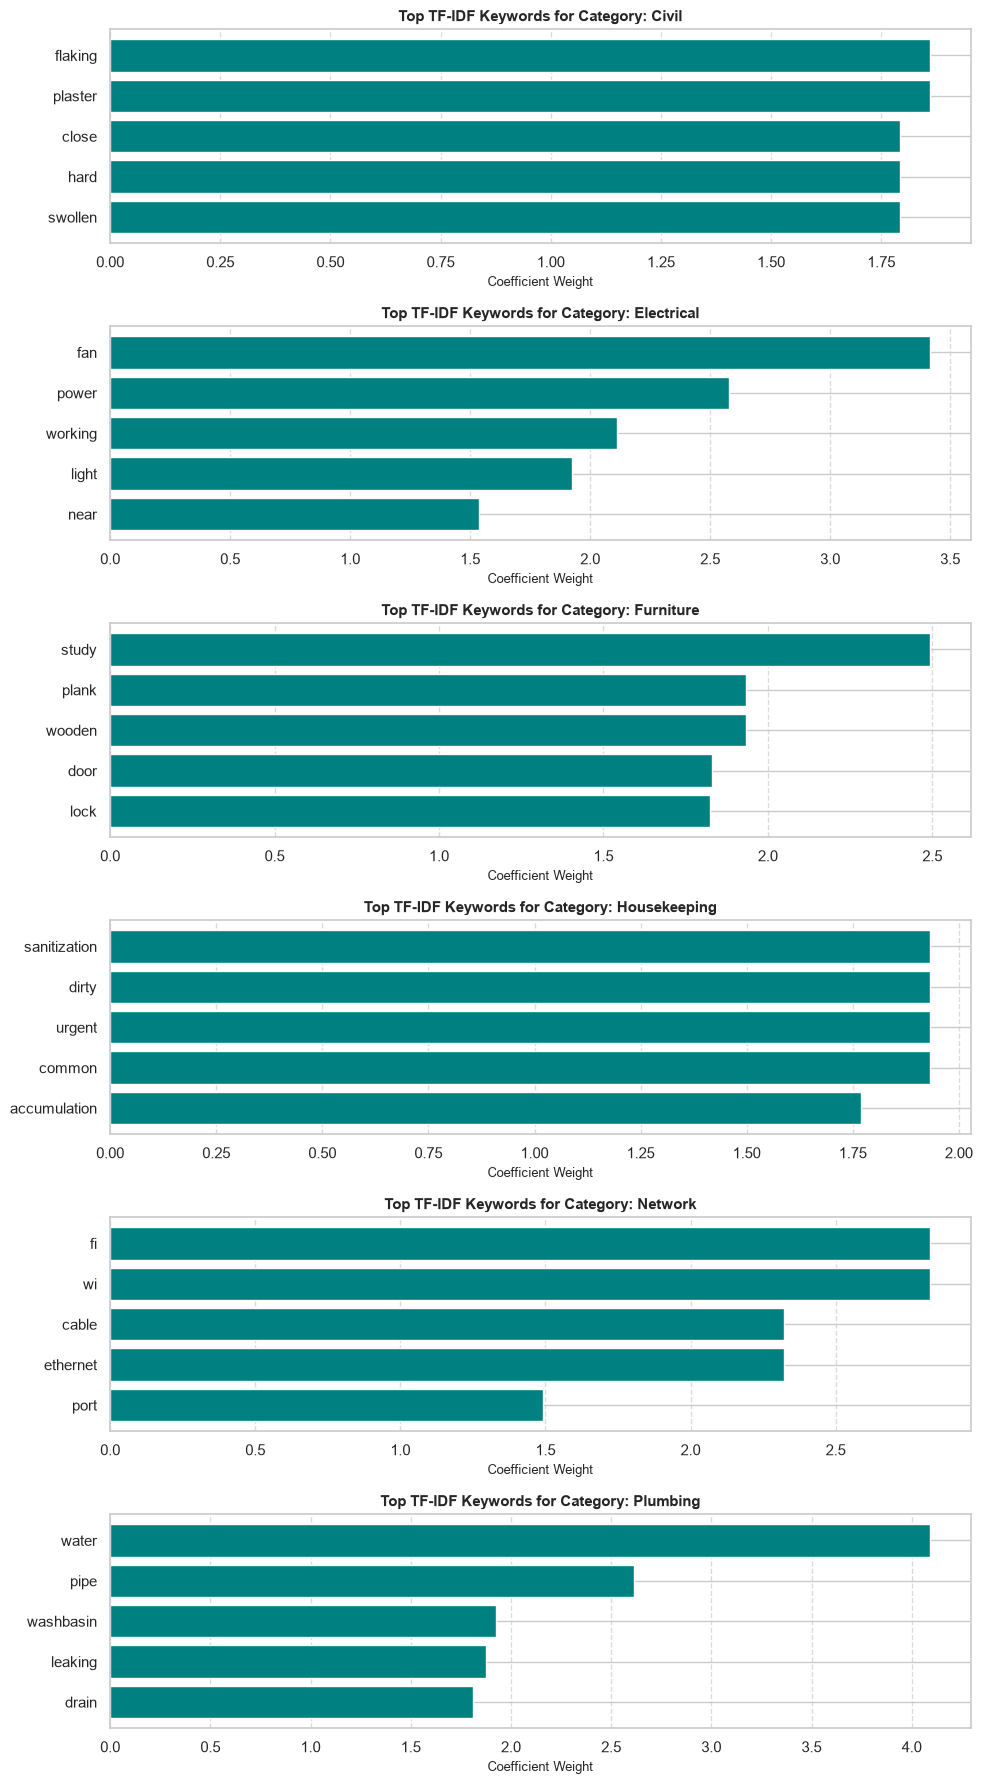

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np

# Ensure we have test predictions from earlier
# X_test_text, y_test, clf, and tfidf should already be defined in your notebook scope
y_pred = clf.predict(X_test)

# 1. Confusion Matrix Heatmap for Logistic Regression Classifier
plt.figure(figsize=(12, 10))
cm = confusion_matrix(y_test, y_pred, labels=clf.classes_)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=clf.classes_, yticklabels=clf.classes_)
plt.title('Logistic Regression Confusion Matrix (100% Accuracy)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Predicted Category', fontsize=12, fontweight='bold')
plt.ylabel('Actual Category', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# 2. Top TF-IDF Feature Coefficients / Importance per Category
def plot_top_tfidf_features(vectorizer, classifier, n_top_features=5):
    feature_names = np.array(vectorizer.get_feature_names_out())
    classes = classifier.classes_
    
    fig, axes = plt.subplots(len(classes), 1, figsize=(10, 3 * len(classes)), sharex=False)
    if len(classes) == 1:
        axes = [axes]
        
    for i, class_name in enumerate(classes):
        # Get top coefficients for each class
        top_coefficients = classifier.coef_[i].argsort()[-n_top_features:][::-1]
        top_features = feature_names[top_coefficients]
        top_scores = classifier.coef_[i][top_coefficients]
        
        ax = axes[i]
        ax.barh(top_features[::-1], top_scores[::-1], color='teal')
        ax.set_title(f'Top TF-IDF Keywords for Category: {class_name}', fontsize=11, fontweight='bold')
        ax.set_xlabel('Coefficient Weight', fontsize=9)
        ax.grid(axis='x', linestyle='--', alpha=0.7)
        
    plt.tight_layout()
    plt.show()

# Run feature importance plot
plot_top_tfidf_features(tfidf, clf, n_top_features=5)